# Rates, FX and crypto regime dashboard

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UnbiasedAlpha/aurastream-python/blob/main/examples/02_cross_asset_dashboard.ipynb)

Bitcoin, ether, a gold-backed token, the euro and the yen, euro-area yields and the Fed's policy rate, from **three sources through one client**, then drawdowns, the yield curve and rolling correlations to see which regime the market is in.

**Sources:** `binance` (public market data), `sdmx` (ECB and BIS statistics) · no provider accounts needed · **Calls used:** 4 of your 500 free monthly calls

In [1]:
%pip install -q "aurastream[pandas]" matplotlib

import os, getpass
if not os.environ.get("AURASTREAM_API_KEY"):
    # Free key, 500 calls/month, no card: https://aurastream.unbiased-alpha.com
    os.environ["AURASTREAM_API_KEY"] = getpass.getpass("AuraStream API key: ")

import pandas as pd
import matplotlib.pyplot as plt
from aurastream_client import AuraStream

client = AuraStream()

## 1. Crypto and gold from Binance

`PAXGUSDT` is Pax Gold, a token backed by one troy ounce of London gold; it tracks the gold price closely and trades around the clock.

In [2]:
START, END = "2021-01-01", "2025-10-31"

crypto = client.get_panel(["BTCUSDT", "ETHUSDT", "PAXGUSDT"], START, END, "1d", source="binance")
# Binance daily bars are stamped at their close (midnight UTC): date them by the day they cover
crypto.index = crypto.index.normalize() - pd.Timedelta(days=1)
crypto.columns = ["Bitcoin", "Ether", "Gold (PAXG)"]
crypto.tail()

,Bitcoin,Ether,Gold (PAXG)
timestamp,,,
2025-10-27 00:00:00+00:00,114107.65,4120.15,3992.20
2025-10-28 00:00:00+00:00,112898.45,3979.20,3968.36
2025-10-29 00:00:00+00:00,110021.29,3902.99,3956.23
2025-10-30 00:00:00+00:00,108322.88,3805.09,4034.25
2025-10-31 00:00:00+00:00,109608.01,3847.99,4000.16


## 2. FX and rates from the ECB and the BIS

SDMX series are named `AGENCY,DATAFLOW,VERSION/KEY`. They come back at their own frequency with their full history, so the notebook trims them to the same window.

In [3]:
FX = {
    "ECB,EXR,1.0/D.USD.EUR.SP00.A": "EUR/USD",
    "ECB,EXR,1.0/D.JPY.EUR.SP00.A": "EUR/JPY",
}
YIELDS = {
    "ECB,YC,1.0/B.U2.EUR.4F.G_N_A.SV_C_YM.SR_2Y": "Euro 2y",
    "ECB,YC,1.0/B.U2.EUR.4F.G_N_A.SV_C_YM.SR_10Y": "Euro 10y",
}

def sdmx(series, db):
    df = client.get_panel(list(series), START, END, "1d", source="sdmx", db=db, field="Value")
    df.index = df.index.normalize()
    return df.rename(columns=series).loc[START:END]

fx = sdmx(FX, "ECB")
fx["USD/JPY"] = fx["EUR/JPY"] / fx["EUR/USD"]
yields = sdmx(YIELDS, "ECB")
fed = sdmx({"BIS,WS_CBPOL,1.0/D.US": "Fed policy rate"}, "BIS")

pd.concat([fx, yields, fed], axis=1, sort=True).dropna().tail()

,EUR/JPY,EUR/USD,USD/JPY,Euro 10y,Euro 2y,Fed policy rate
timestamp,,,,,,
2025-10-27 00:00:00+00:00,177.93,1.1640,152.860825,2.704480,1.952580,4.125
2025-10-28 00:00:00+00:00,177.11,1.1630,152.287188,2.697798,1.950218,4.125
2025-10-29 00:00:00+00:00,177.07,1.1636,152.174287,2.702991,1.944996,4.125
2025-10-30 00:00:00+00:00,178.37,1.1550,154.432900,2.716162,1.966546,3.875
2025-10-31 00:00:00+00:00,178.14,1.1554,154.180370,2.721603,1.949646,3.875


## 3. Performance and drawdowns

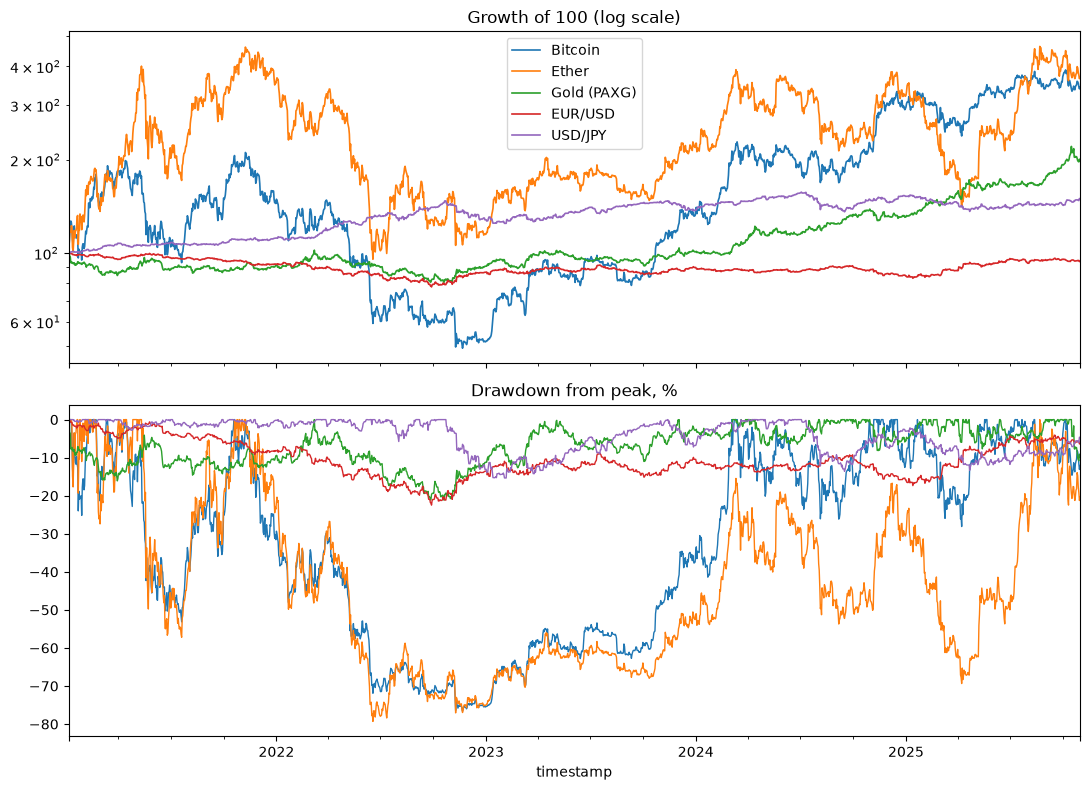

In [4]:
prices = pd.concat([crypto, fx[["EUR/USD", "USD/JPY"]]], axis=1, sort=True).ffill().dropna()
norm = prices / prices.iloc[0] * 100
drawdown = prices / prices.cummax() - 1

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
norm.plot(ax=a1, logy=True, lw=1.2)
a1.set_title("Growth of 100 (log scale)")
(drawdown * 100).plot(ax=a2, lw=1, legend=False)
a2.set_title("Drawdown from peak, %")
plt.tight_layout()

## 4. The euro curve and the Fed

When the 10-year yield sits below the 2-year (an inverted curve), markets expect rates to fall. The Fed's policy rate shows where US rates actually were.

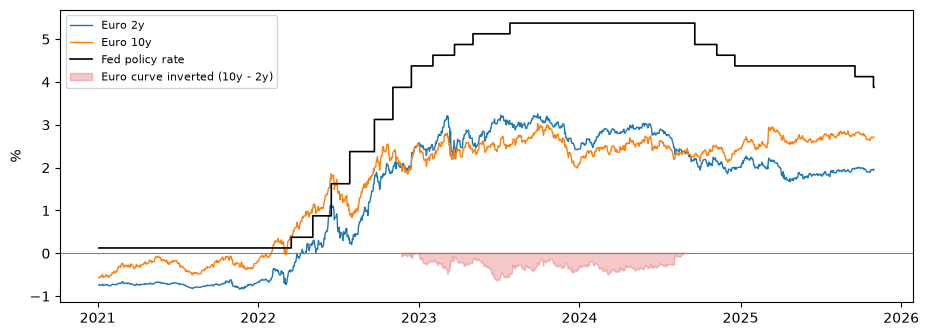

In [5]:
curve = pd.concat([yields, fed], axis=1, sort=True).ffill().dropna()
slope = curve["Euro 10y"] - curve["Euro 2y"]

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(curve.index, curve["Euro 2y"], label="Euro 2y", lw=1)
ax.plot(curve.index, curve["Euro 10y"], label="Euro 10y", lw=1)
ax.step(curve.index, curve["Fed policy rate"], where="post", color="black", lw=1.2, label="Fed policy rate")
ax.fill_between(slope.index, 0, slope, where=slope < 0, color="tab:red", alpha=0.25, label="Euro curve inverted (10y - 2y)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("%")
ax.legend(loc="upper left", fontsize=8);

## 5. Is bitcoin trading like gold or like a risk asset?

Rolling 3-month correlation of daily returns: bitcoin against the gold token, and against ether.

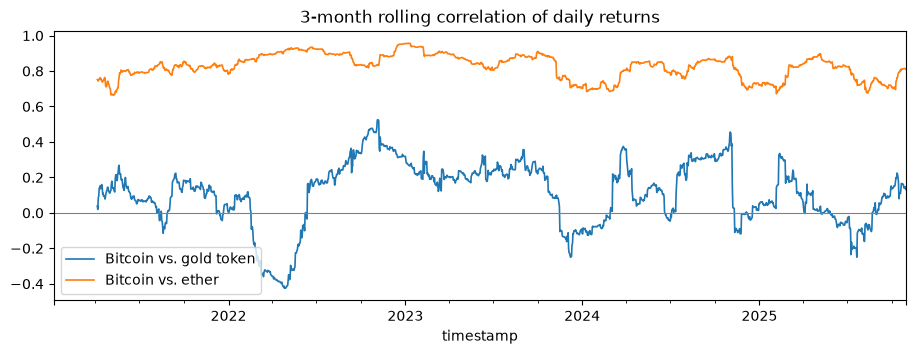

In [6]:
rets = prices.pct_change().dropna()
fig, ax = plt.subplots(figsize=(11, 3.5))
rets["Bitcoin"].rolling(91).corr(rets["Gold (PAXG)"]).plot(ax=ax, lw=1.2, label="Bitcoin vs. gold token")
rets["Bitcoin"].rolling(91).corr(rets["Ether"]).plot(ax=ax, lw=1.2, label="Bitcoin vs. ether")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("3-month rolling correlation of daily returns")
ax.legend(loc="lower left");

## 6. Correlation heatmap: last 3 months vs. full sample

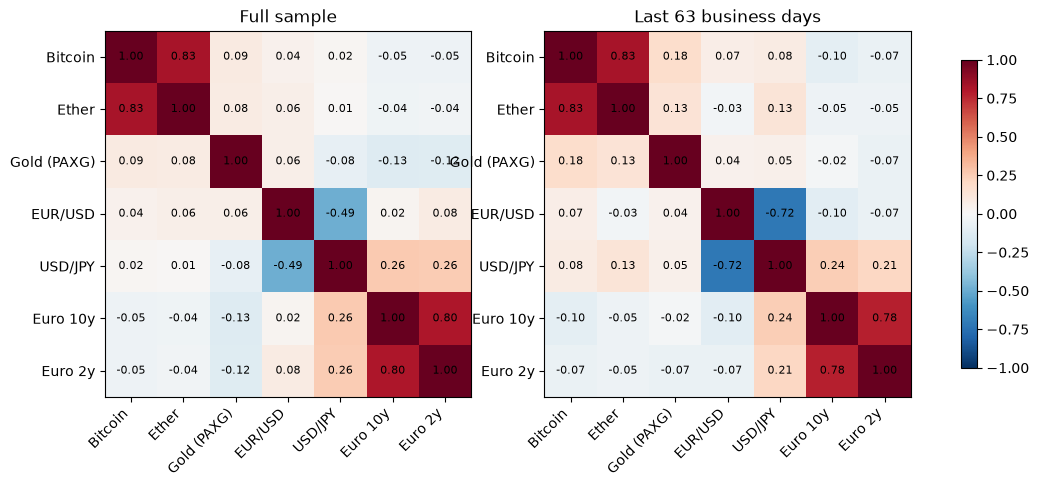

In [7]:
# Prices in returns, yields in daily changes (business days, when FX and rates are quoted)
daily = pd.concat([prices.pct_change(), yields.diff()], axis=1, sort=True).loc[fx.index].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (title, sample) in zip(axes, [("Full sample", daily), ("Last 63 business days", daily.tail(63))]):
    c = sample.corr()
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(c)), c.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(c)), c.columns)
    for i in range(len(c)):
        for j in range(len(c)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

## Extend it

Same client, same call shape:

```python
client.get_frame("CPIAUCSL", "2020-01-01", "2025-10-31", "1m", source="fred", credentials={"key": FRED_KEY})  # US macro, free FRED key
client.get_frame("tga", "2024-01-01", "2025-10-31", source="treasury")                                         # Treasury cash balance
client.get_frame("BTC", "2024-01-01", "2025-10-31", "1h", source="hyperliquid")                                # on-chain perps
```

US equities come with your own account at a broker or vendor AuraStream connects to (Alpaca, Polygon, FirstRate).

---
### Next steps

- **Get a free key**: 500 calls a month, no card: [aurastream.unbiased-alpha.com](https://aurastream.unbiased-alpha.com)
- **Docs**: [aurastream.unbiased-alpha.com/docs](https://aurastream.unbiased-alpha.com/docs/)
- **Use it from Claude or ChatGPT**: `pip install aurastream-mcp`
- Found this useful? ⭐ the repo: [github.com/UnbiasedAlpha/aurastream-python](https://github.com/UnbiasedAlpha/aurastream-python)

*Built by [Unbiased Alpha](https://unbiased-alpha.com). For research and education only; not investment advice.*